# Trening sieci U-Net (PyTorch + CUDA / Google Colab) — segmentacja i wektoryzacja pól

Notebook uczy **3-klasowy** model **U-Net** w PyTorch (`0 = inne`, `1 = pole`, `2 = granica_pola` o grubości 1 px, `255 = ignorowane`) na **7 kanałach** (`RED`, `GREEN`, `BLUE`, `NIR`, `SWIR16`, `DOY_SIN`, `DOY_COS`) i do 3 scen/miesiąc w roku treningowym **2024**:
1. **Dane treningowe (`2024`) vs walidacyjne/testowe (`2025`)**: normalizacja per kanał liczona wyłącznie na danych z **2024**, walidacja i niezależny test na niewidzianym roku **2025**.
2. **Kaflowanie `256x256` + filtrowanie**: cięcie rastrów na kwadraty `256x256` i odrzucanie kafli z **>= 90% pikseli błędnych**.
3. **Trening U-Net (CUDA AMP)** + **walidacja (2025)**: macierz pomyłek `3x3`, macierz korelacji Pearsona oraz metryki `Precision / Recall / F1 / IoU / Kappa`.
4. **Wektoryzacja rozdzielonych pól**: wykorzystanie klasy `granica_pola` do rozdzielenia stykających się działek przed wektoryzacją i eksport do **GeoPackage (`.gpkg`, `EPSG:2180`)** oraz **GeoJSON (`.geojson`, `EPSG:4326`)**.

In [100]:
import importlib.util
import os
from pathlib import Path
import random
import subprocess
import sys
import zipfile
import numpy as np
from scipy.ndimage import binary_opening, label

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    _missing = [p for p in ("rasterio", "geopandas", "shapely", "scipy") if importlib.util.find_spec(p) is None]
    if _missing:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
else:
    prefix = Path(sys.prefix).resolve()
    for _var in ("PROJ_LIB", "PROJ_DATA"):
        _val = os.environ.get(_var)
        if _val:
            try:
                if not Path(_val).resolve().is_relative_to(prefix):
                    os.environ.pop(_var, None)
            except OSError:
                os.environ.pop(_var, None)

# Konfiguracja Google Drive / Colab:
USE_GOOGLE_DRIVE = True   # Automatycznie montuje Google Drive w Colab (/content/drive)
COLAB_DATA_DIR = None     # Opcjonalna dokładna ścieżka do enter_data, np. "/content/drive/MyDrive/enter_data"

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import geometry_mask, shapes
from scipy.ndimage import binary_closing, binary_fill_holes, binary_opening, distance_transform_edt, label as nd_label
from shapely.geometry import shape
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

# Parametry czasowe i hiperparametry modelu / wektoryzacji
TRAIN_YEAR = 2024
EVAL_YEAR = 2025

TILE_SIZE = 256
STRIDE = 128
MAX_INVALID_RATIO = 0.90
NUM_CLASSES = 3
IGNORE_INDEX = 255
CLASS_NAMES = {0: "inne", 1: "pole", 2: "granica_pola"}

BATCH_SIZE = 8
EPOCHS = 30
LR = 1e-3
WEIGHT_DECAY = 1e-4
SEED = 42

PROB_THRESHOLD = 0.45
BOUNDARY_THRESHOLD = 0.35
MIN_FIELD_AREA_HA = 0.10
SIMPLIFY_TOL_M = 5.0
EXCLUDE_BANDS = {"RED", "GREEN", "BLUE", "SWIR22", "DOY_SIN", "DOY_COS"}


def _has_aoi_or_tifs(path: Path) -> bool:
    if not path.exists():
        return False
    if any((d / "label_mask.tif").exists() for d in path.glob("aoi_*") if d.is_dir()):
        return True
    return any(p.name != "label_mask.tif" and not p.name.startswith("pred_") for p in path.glob("*.tif"))


def _extract_tifs_from_zip(zip_path: Path, target_dir: Path) -> int:
    count = 0
    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            if member.is_dir() or "__MACOSX" in member.filename:
                continue
            parts = Path(member.filename).parts
            fname = parts[-1]
            if fname.startswith("._") or Path(fname).suffix.lower() not in {".tif", ".tiff", ".csv"}:
                continue
            aoi_parts = [p for p in parts[:-1] if p.startswith("aoi_")]
            dest = (target_dir / aoi_parts[-1] / fname) if aoi_parts else (target_dir / fname)
            dest.parent.mkdir(parents=True, exist_ok=True)
            if not dest.exists():
                with zf.open(member) as src, open(dest, "wb") as dst:
                    dst.write(src.read())
            count += 1
    return count


def _resolve_data_root(
    in_colab: bool = IN_COLAB,
    use_gdrive: bool = USE_GOOGLE_DRIVE,
    colab_data_dir: str | Path | None = COLAB_DATA_DIR,
    content_root: Path = Path("/content"),
    drive_root: Path = Path("/content/drive/MyDrive"),
) -> tuple[Path, Path, Path]:
    if in_colab and use_gdrive and not drive_root.exists():
        from google.colab import drive
        drive.mount("/content/drive")

    direct = ([Path(colab_data_dir)] if colab_data_dir else []) + [
        Path("field_classification/enter_data"), Path("enter_data")
    ]
    if in_colab:
        direct.extend([
            content_root / "enter_data",
            content_root / "field_classification/enter_data",
            drive_root / "enter_data",
            drive_root / "field_classification/enter_data",
            drive_root / "Colab Notebooks/enter_data",
            drive_root / "Colab Notebooks/field_classification/enter_data",
        ])

    data_root = next((c for c in direct if _has_aoi_or_tifs(c)), None)

    if data_root is None:
        skip = {"sample_data", "__pycache__", ".git", ".ipynb_checkpoints", "drive"}
        roots = [r for r in ([content_root, drive_root] if in_colab else [Path(".")]) if r.exists()]
        for root in roots:
            r_depth = len(root.resolve().parts)
            for cur, dirs, files in os.walk(root):
                cur_p = Path(cur)
                dirs[:] = [d for d in sorted(dirs) if not d.startswith(".") and d not in skip]
                if len(cur_p.resolve().parts) - r_depth >= 4:
                    dirs[:] = []
                if cur_p.name.startswith("aoi_") and "label_mask.tif" in files:
                    data_root = cur_p.parent
                    break
                if any(f.startswith("s2_l2a_") and f.endswith(".tif") for f in files):
                    data_root = cur_p.parent if cur_p.name.startswith("aoi_") else cur_p
                    break
            if data_root is not None:
                break

    if data_root is None and in_colab:
        target_dir = content_root / "enter_data"
        zip_cands = []
        for zr in (content_root, drive_root, drive_root / "Colab Notebooks"):
            if zr.exists():
                zip_cands.extend(sorted(zr.glob("*.zip"), key=lambda p: ("enter_data" not in p.name.lower(), p.name.lower())))
        for zp in zip_cands:
            if _extract_tifs_from_zip(zp, target_dir) > 0 and _has_aoi_or_tifs(target_dir):
                print(f"Rozpakowano archiwum {zp.name} -> {target_dir}")
                data_root = target_dir
                break

    if data_root is None:
        data_root = (drive_root / "enter_data") if (in_colab and drive_root.exists()) else Path("field_classification/enter_data")

    base_dir = data_root.parent if data_root.name == "enter_data" else data_root
    return base_dir, data_root, base_dir / "models"


def _resolve_selected_bands(
    sample_raster: Path | None,
    exclude_bands: set[str] = EXCLUDE_BANDS,
) -> tuple[list[int], list[str]]:
    """Wybierz indeksy (1-based) oraz nazwy kanałów z pominięciem wykluczonych pasm (NDVI, NDWI, SWIR22)."""
    if sample_raster is not None and sample_raster.exists():
        with rasterio.open(sample_raster) as src:
            descs = list(src.descriptions or ())
            if descs and any(descs):
                kept = [(i, d or f"CH_{i-1}") for i, d in enumerate(descs, start=1) if (d or f"CH_{i-1}") not in exclude_bands]
                if kept:
                    return [i for i, _ in kept], [name for _, name in kept]
    return [1, 2, 3, 4, 5, 9, 10], ["NDVI", "NDWI", "NIR", "SWIR16"]


def discover_aoi_datasets(data_root: Path, train_year: int = TRAIN_YEAR, eval_year: int = EVAL_YEAR) -> list[dict]:
    """Wykryj podfoldery AOI i podziel sceny na Train (2024) oraz Val/Test (2025)."""
    aoi_dirs = sorted(d for d in data_root.glob("aoi_*") if d.is_dir() and (d / "label_mask.tif").exists())
    if not aoi_dirs and (data_root / "label_mask.tif").exists():
        aoi_dirs = [data_root]

    datasets = []
    for d in aoi_dirs:
        t_train = sorted(d.glob(f"s2_l2a_{train_year}_*.tif"))
        t_eval = sorted(d.glob(f"s2_l2a_{eval_year}_*.tif"))
        val_r = t_eval[0::2]
        test_r = t_eval[1::2] if len(t_eval) >= 2 else t_eval[:]
        datasets.append({
            "name": d.name if d != data_root else "aoi_1",
            "dir": d,
            "label_path": d / "label_mask.tif",
            "train_rasters": t_train,
            "val_rasters": val_r,
            "test_rasters": test_r,
            "eval_rasters": t_eval,
        })
    return datasets


BASE_DIR, DATA_DIR, MODEL_DIR = _resolve_data_root()
AOI_DATASETS = discover_aoi_datasets(DATA_DIR)
_sample_raster = next(((a["train_rasters"] or a["eval_rasters"])[0] for a in AOI_DATASETS if (a["train_rasters"] or a["eval_rasters"])), None)
SELECTED_BAND_INDICES, SELECTED_BAND_NAMES = _resolve_selected_bands(_sample_raster)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print(f"Środowisko: {'Colab' if IN_COLAB else 'Lokalne'} | Urządzenie: {DEVICE} | AMP: {USE_AMP}")
if USE_AMP:
    print(f"GPU: {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB)")
print(f"DATA_DIR:  {DATA_DIR.resolve()}")
print(f"MODEL_DIR: {MODEL_DIR.resolve()}")
for _aoi in AOI_DATASETS:
    print(f"  [{_aoi['name']}] Train {TRAIN_YEAR}: {len(_aoi['train_rasters'])} | Val {EVAL_YEAR}: {len(_aoi['val_rasters'])} | Test {EVAL_YEAR}: {len(_aoi['test_rasters'])}")
print(f"Kanały wejściowe ({len(SELECTED_BAND_NAMES)}): {SELECTED_BAND_NAMES} (wykluczono: {sorted(EXCLUDE_BANDS)})")
if not AOI_DATASETS:
    print("UWAGA: Nie wykryto żadnych folderów aoi_* z maską label_mask.tif w DATA_DIR!")

Środowisko: Colab | Urządzenie: cuda | AMP: True
GPU: Tesla T4 (15.6 GB)
DATA_DIR:  /content/drive/MyDrive/enter_data
MODEL_DIR: /content/drive/MyDrive/models
  [aoi_1] Train 2024: 23 | Val 2025: 4 | Test 2025: 4
  [aoi_3] Train 2024: 25 | Val 2025: 4 | Test 2025: 4
Kanały wejściowe (4): ['NIR', 'SWIR16', 'NDVI', 'NDWI'] (wykluczono: ['BLUE', 'DOY_COS', 'DOY_SIN', 'GREEN', 'RED', 'SWIR22'])


In [72]:
def pad_to_grid(
    img: np.ndarray,
    mask: np.ndarray,
    tile_size: int = TILE_SIZE,
    ignore_index: int = IGNORE_INDEX,
) -> tuple[np.ndarray, np.ndarray]:
    """Dopełnij prawą i dolną krawędź obrazu i maski do wielokrotności tile_size (>= 256)."""
    _, h, w = img.shape
    h_pad = max(tile_size, int(np.ceil(h / tile_size)) * tile_size)
    w_pad = max(tile_size, int(np.ceil(w / tile_size)) * tile_size)
    if h_pad == h and w_pad == w:
        return img, mask
    img_pad = np.pad(img, ((0, 0), (0, h_pad - h), (0, w_pad - w)), mode="constant", constant_values=np.nan)
    mask_pad = np.pad(mask, ((0, h_pad - h), (0, w_pad - w)), mode="constant", constant_values=ignore_index)
    return img_pad, mask_pad


def _sliding_starts(length: int, tile_size: int, stride: int) -> list[int]:
    if length <= tile_size:
        return [0]
    starts = list(range(0, length - tile_size + 1, stride))
    if starts[-1] != length - tile_size:
        starts.append(length - tile_size)
    return starts


def extract_valid_tiles(
    raster_label_pairs: list[tuple[Path, Path, str]],
    band_indices: list[int] = SELECTED_BAND_INDICES,
    tile_size: int = TILE_SIZE,
    stride: int = STRIDE,
    max_invalid_ratio: float = MAX_INVALID_RATIO,
    ignore_index: int = IGNORE_INDEX,
) -> tuple[list[dict], dict]:
    """Potnij rastry na kwadraty 256x256 i odrzuć kafle z >= 90% pikseli błędnych."""
    tiles: list[dict] = []
    total_candidates = 0
    rejected_invalid = 0
    class_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
    mask_cache: dict[Path, np.ndarray] = {}

    for rpath, mpath, aoi_name in raster_label_pairs:
        if mpath not in mask_cache:
            with rasterio.open(mpath) as m_src:
                mask_cache[mpath] = m_src.read(1).astype(np.uint8)
        mask = mask_cache[mpath]

        with rasterio.open(rpath) as src:
            img = src.read(band_indices).astype(np.float32)

        if img.shape[1:] != mask.shape:
            raise ValueError(f"[{aoi_name}] Niezgodny kształt {rpath.name} {img.shape[1:]} vs maska {mask.shape}")

        img_pad, mask_pad = pad_to_grid(img, mask, tile_size=tile_size, ignore_index=ignore_index)
        _, h_pad, w_pad = img_pad.shape

        for y0 in _sliding_starts(h_pad, tile_size, stride):
            for x0 in _sliding_starts(w_pad, tile_size, stride):
                total_candidates += 1
                tile_x = img_pad[:, y0 : y0 + tile_size, x0 : x0 + tile_size].copy()
                tile_y = mask_pad[y0 : y0 + tile_size, x0 : x0 + tile_size].copy()

                bad_spectral = ~np.all(np.isfinite(tile_x), axis=0)
                invalid_ratio = float(np.mean(bad_spectral | (tile_y == ignore_index)))
                if invalid_ratio >= max_invalid_ratio:
                    rejected_invalid += 1
                    continue

                tile_y[bad_spectral] = ignore_index
                for cls_id in range(NUM_CLASSES):
                    class_counts[cls_id] += int(np.sum(tile_y == cls_id))

                tiles.append({
                    "image": tile_x,
                    "mask": tile_y,
                    "aoi": aoi_name,
                    "source": rpath.name,
                    "y0": y0,
                    "x0": x0,
                    "invalid_ratio": invalid_ratio,
                })

    stats = {
        "n_rasters": len(raster_label_pairs),
        "total_tiles": total_candidates,
        "kept_tiles": len(tiles),
        "rejected_tiles": rejected_invalid,
        "class_counts": {int(c): int(class_counts[c]) for c in range(NUM_CLASSES)},
    }
    return tiles, stats


if not AOI_DATASETS:
    raise FileNotFoundError(f"Brak wykrytych zbiorów AOI w {DATA_DIR.resolve()}")

train_pairs = [(r, a["label_path"], a["name"]) for a in AOI_DATASETS for r in a["train_rasters"]]
val_pairs = [(r, a["label_path"], a["name"]) for a in AOI_DATASETS for r in a["val_rasters"]]
test_pairs = [(r, a["label_path"], a["name"]) for a in AOI_DATASETS for r in a["test_rasters"]]

assert train_pairs, f"Brak scen treningowych z roku {TRAIN_YEAR}!"
assert val_pairs and test_pairs, f"Brak scen walidacyjnych/testowych z roku {EVAL_YEAR}!"

train_tiles, train_stats = extract_valid_tiles(train_pairs, band_indices=SELECTED_BAND_INDICES)
val_tiles, val_stats = extract_valid_tiles(val_pairs, band_indices=SELECTED_BAND_INDICES)
test_tiles, test_stats = extract_valid_tiles(test_pairs, band_indices=SELECTED_BAND_INDICES)
assert train_tiles and val_tiles and test_tiles, "Jeden ze zbiorów (train/val/test) jest pusty po filtrze >=90%!"

IN_CHANNELS = train_tiles[0]["image"].shape[0]
for split_label, st in ((f"Train ({TRAIN_YEAR})", train_stats), (f"Val ({EVAL_YEAR})", val_stats), (f"Test ({EVAL_YEAR})", test_stats)):
    print(f"{split_label:12s}: rastry={st['n_rasters']:2d} | kafle {TILE_SIZE}x{TILE_SIZE}={st['kept_tiles']:2d} (odrzuc.={st['rejected_tiles']}) | piksele={st['class_counts']}")

Train (2024): rastry=48 | kafle 256x256=48 (odrzuc.=0) | piksele={0: 295897, 1: 531578, 2: 210086}
Val (2025)  : rastry= 8 | kafle 256x256= 8 (odrzuc.=0) | piksele={0: 48584, 1: 91991, 2: 36285}
Test (2025) : rastry= 8 | kafle 256x256= 8 (odrzuc.=0) | piksele={0: 48426, 1: 92300, 2: 36319}


In [73]:
def compute_channel_stats(tiles: list[dict]) -> tuple[np.ndarray, np.ndarray]:
    """Wylicz średnią i odchylenie standardowe per kanał wyłącznie na zbiorze treningowym (2024)."""
    n_ch = tiles[0]["image"].shape[0]
    ch_sum = np.zeros(n_ch, dtype=np.float64)
    ch_sq = np.zeros(n_ch, dtype=np.float64)
    ch_cnt = np.zeros(n_ch, dtype=np.int64)

    for t in tiles:
        arr = t["image"]
        for c in range(n_ch):
            vals = arr[c][np.isfinite(arr[c])].astype(np.float64)
            if vals.size:
                ch_sum[c] += float(vals.sum())
                ch_sq[c] += float(np.square(vals).sum())
                ch_cnt[c] += int(vals.size)

    mean = ch_sum / np.maximum(ch_cnt, 1)
    var = np.maximum(ch_sq / np.maximum(ch_cnt, 1) - np.square(mean), 0.0)
    std = np.sqrt(var)
    std = np.where(std < 1e-6, 1.0, std)
    return mean.astype(np.float32), std.astype(np.float32)


class SegmentationTileDataset(Dataset):
    def __init__(self, tiles: list[dict], mean: np.ndarray, std: np.ndarray, augment: bool = False):
        self.tiles = tiles
        self.mean = mean[:, None, None]
        self.std = std[:, None, None]
        self.augment = augment

    def __len__(self) -> int:
        return len(self.tiles)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, torch.Tensor]:
        item = self.tiles[idx]
        x = (item["image"] - self.mean) / self.std
        x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
        y = item["mask"].astype(np.int64)

        x_t = torch.from_numpy(x)
        y_t = torch.from_numpy(y)

        if self.augment:
            if random.random() < 0.5:
                x_t = torch.flip(x_t, dims=[2])
                y_t = torch.flip(y_t, dims=[1])
            if random.random() < 0.5:
                x_t = torch.flip(x_t, dims=[1])
                y_t = torch.flip(y_t, dims=[0])
            k = random.randint(0, 3)
            if k:
                x_t = torch.rot90(x_t, k=k, dims=(1, 2))
                y_t = torch.rot90(y_t, k=k, dims=(0, 1))

        return x_t.contiguous(), y_t.contiguous()


channel_mean, channel_std = compute_channel_stats(train_tiles)
train_ds = SegmentationTileDataset(train_tiles, channel_mean, channel_std, augment=True)
val_ds = SegmentationTileDataset(val_tiles, channel_mean, channel_std, augment=False)
test_ds = SegmentationTileDataset(test_tiles, channel_mean, channel_std, augment=False)

train_loader = DataLoader(train_ds, batch_size=min(BATCH_SIZE, len(train_ds)), shuffle=True, pin_memory=USE_AMP)
val_loader = DataLoader(val_ds, batch_size=min(BATCH_SIZE, len(val_ds)), shuffle=False, pin_memory=USE_AMP)
test_loader = DataLoader(test_ds, batch_size=min(BATCH_SIZE, len(test_ds)), shuffle=False, pin_memory=USE_AMP)

print(f"DataLoadery -> train({TRAIN_YEAR})={len(train_ds)} | val({EVAL_YEAR})={len(val_ds)} | test({EVAL_YEAR})={len(test_ds)}")
print("Średnia per kanał (2024):", np.round(channel_mean, 4))
print("Std per kanał (2024):    ", np.round(channel_std, 4))

DataLoadery -> train(2024)=48 | val(2025)=8 | test(2025)=8
Średnia per kanał (2024): [ 0.1903  0.135   0.8601 -0.9294]
Std per kanał (2024):     [0.0804 0.0759 0.2332 0.143 ]


In [74]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, dropout: float = 0.0):
        super().__init__()
        layers: list[nn.Module] = [
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ]
        if dropout > 0.0:
            layers.append(nn.Dropout2d(dropout))
        layers.extend([
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        ])
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class UNet(nn.Module):
    """Klasyczny PyTorch U-Net (4 poziomy) dla segmentacji binarnej (inne vs pole)."""

    def __init__(self, in_channels: int, num_classes: int = 3, base_channels: int = 32, dropout: float = 0.1):
        super().__init__()
        c = base_channels
        self.enc1 = DoubleConv(in_channels, c)
        self.enc2 = DoubleConv(c, c * 2)
        self.enc3 = DoubleConv(c * 2, c * 4)
        self.enc4 = DoubleConv(c * 4, c * 8, dropout=dropout)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(c * 8, c * 16, dropout=dropout)

        self.up4 = nn.ConvTranspose2d(c * 16, c * 8, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(c * 16, c * 8)
        self.up3 = nn.ConvTranspose2d(c * 8, c * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(c * 8, c * 4)
        self.up2 = nn.ConvTranspose2d(c * 4, c * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(c * 4, c * 2)
        self.up1 = nn.ConvTranspose2d(c * 2, c, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(c * 2, c)

        self.head = nn.Conv2d(c, num_classes, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)


model = UNet(in_channels=IN_CHANNELS, num_classes=NUM_CLASSES, base_channels=32, dropout=0.1).to(DEVICE)
with torch.no_grad():
    _test_out = model(torch.zeros((2, IN_CHANNELS, TILE_SIZE, TILE_SIZE), device=DEVICE))
assert tuple(_test_out.shape) == (2, NUM_CLASSES, TILE_SIZE, TILE_SIZE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model UNet gotowy na {DEVICE} | Parametry: {n_params:,} | Wyjście: {tuple(_test_out.shape)}")

Model UNet gotowy na cuda | Parametry: 7,763,395 | Wyjście: (2, 3, 256, 256)


In [75]:
def compute_class_weights(tiles: list[dict], num_classes: int = NUM_CLASSES) -> torch.Tensor:
    counts = np.zeros(num_classes, dtype=np.float64)
    for t in tiles:
        m = t["mask"]
        for c in range(num_classes):
            counts[c] += float(np.sum(m == c))
    present = counts > 0
    total = float(counts[present].sum())
    n_present = max(1, int(present.sum()))
    weights = np.ones(num_classes, dtype=np.float32)
    if total > 0:
        for c in range(num_classes):
            if counts[c] > 0:
                weights[c] = np.clip(total / (n_present * counts[c]), 0.25, 10.0)
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)


class CombinedSegLoss(nn.Module):
    def __init__(self, class_weights: torch.Tensor, num_classes: int = 3, ignore_index: int = 255):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights, ignore_index=ignore_index)
        self.num_classes = num_classes
        self.ignore_index = ignore_index

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        valid = targets != self.ignore_index
        if not torch.any(valid):
            return logits.sum() * 0.0

        loss_ce = self.ce(logits, targets)
        probs = torch.softmax(logits, dim=1)
        safe_targets = torch.where(valid, targets, 0)

        dice_losses = []
        valid_f = valid.unsqueeze(1).float()
        for c in range(self.num_classes):
            t_c = (safe_targets == c).unsqueeze(1).float() * valid_f
            if float(t_c.sum()) == 0.0:
                continue
            p_c = probs[:, c : c + 1] * valid_f
            inter = (p_c * t_c).sum()
            union = p_c.sum() + t_c.sum()
            dice_losses.append(1.0 - (2.0 * inter + 1e-6) / (union + 1e-6))

        loss_dice = torch.stack(dice_losses).mean() if dice_losses else loss_ce * 0.0
        return 0.5 * loss_ce + 0.5 * loss_dice


def compute_seg_metrics(preds: torch.Tensor, targets: torch.Tensor, num_classes: int = 3, ignore_index: int = 255) -> dict:
    valid = targets != ignore_index
    if not torch.any(valid):
        return {"pixel_acc": 0.0, "mean_iou": 0.0, "per_class_iou": {}}

    p_v, t_v = preds[valid], targets[valid]
    pixel_acc = float((p_v == t_v).float().mean().item())
    per_class_iou, present_ious = {}, []
    for c in range(num_classes):
        t_c, p_c = t_v == c, p_v == c
        inter = int((p_c & t_c).sum().item())
        union = int((p_c | t_c).sum().item())
        if union == 0:
            per_class_iou[c] = None
        else:
            iou = inter / union
            per_class_iou[c] = iou
            if int(t_c.sum().item()) > 0:
                present_ious.append(iou)

    mean_iou = float(np.mean(present_ious)) if present_ious else 0.0
    return {"pixel_acc": pixel_acc, "mean_iou": mean_iou, "per_class_iou": per_class_iou}


def train_unet(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    channel_mean: np.ndarray,
    channel_std: np.ndarray,
    model_dir: Path = MODEL_DIR,
    epochs: int = EPOCHS,
    lr: float = LR,
    weight_decay: float = WEIGHT_DECAY,
) -> tuple[dict, Path]:
    model_dir.mkdir(parents=True, exist_ok=True)
    ckpt_path = model_dir / "unet_best.pt"

    class_weights = compute_class_weights(train_loader.dataset.tiles, num_classes=NUM_CLASSES)
    print(f"Wagi klas w funkcji straty: {np.round(class_weights.cpu().numpy(), 3).tolist()}")

    criterion = CombinedSegLoss(class_weights, num_classes=NUM_CLASSES, ignore_index=IGNORE_INDEX)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, epochs))
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)

    history = {"train_loss": [], "val_loss": [], "val_miou": [], "val_acc": []}
    best_miou = -1.0

    for epoch in range(1, epochs + 1):
        model.train()
        tr_loss_sum, tr_batches = 0.0, 0
        for x_b, y_b in train_loader:
            x_b = x_b.to(DEVICE, non_blocking=USE_AMP)
            y_b = y_b.to(DEVICE, non_blocking=USE_AMP)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                loss = criterion(model(x_b), y_b)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            tr_loss_sum += float(loss.item())
            tr_batches += 1

        scheduler.step()

        model.eval()
        val_loss_sum, val_batches = 0.0, 0
        all_preds, all_targets = [], []
        with torch.no_grad():
            for x_b, y_b in val_loader:
                x_b = x_b.to(DEVICE, non_blocking=USE_AMP)
                y_b = y_b.to(DEVICE, non_blocking=USE_AMP)
                with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                    logits = model(x_b)
                    loss = criterion(logits, y_b)
                val_loss_sum += float(loss.item())
                val_batches += 1
                all_preds.append(logits.argmax(dim=1).cpu())
                all_targets.append(y_b.cpu())

        tr_loss = tr_loss_sum / max(1, tr_batches)
        val_loss = val_loss_sum / max(1, val_batches)
        metrics = compute_seg_metrics(torch.cat(all_preds, dim=0), torch.cat(all_targets, dim=0), NUM_CLASSES, IGNORE_INDEX)

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(val_loss)
        history["val_miou"].append(metrics["mean_iou"])
        history["val_acc"].append(metrics["pixel_acc"])

        if metrics["mean_iou"] >= best_miou:
            best_miou = metrics["mean_iou"]
            torch.save({
                "model_state_dict": model.state_dict(),
                "channel_mean": channel_mean,
                "channel_std": channel_std,
                "in_channels": IN_CHANNELS,
                "band_indices": SELECTED_BAND_INDICES,
                "band_names": SELECTED_BAND_NAMES,
                "num_classes": NUM_CLASSES,
                "tile_size": TILE_SIZE,
                "ignore_index": IGNORE_INDEX,
                "best_val_miou": best_miou,
                "history": history,
            }, ckpt_path)

        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            iou_str = ", ".join(f"k{c}={v:.3f}" if v is not None else f"k{c}=brak" for c, v in metrics["per_class_iou"].items())
            print(f"Epoka {epoch:02d}/{epochs:02d} | train_loss={tr_loss:.4f} | val_loss={val_loss:.4f} | val_acc={metrics['pixel_acc']:.3f} | val_mIoU={metrics['mean_iou']:.3f} ({iou_str})")

    return history, ckpt_path

Wagi klas w funkcji straty: [1.1690000295639038, 0.6510000228881836, 1.6460000276565552]
Epoka 01/30 | train_loss=0.8193 | val_loss=0.8645 | val_acc=0.364 | val_mIoU=0.244 (k0=0.364, k1=0.142, k2=0.227)
Epoka 05/30 | train_loss=0.6454 | val_loss=1.9200 | val_acc=0.378 | val_mIoU=0.218 (k0=0.124, k1=0.346, k2=0.184)
Epoka 10/30 | train_loss=0.6236 | val_loss=0.5970 | val_acc=0.659 | val_mIoU=0.481 (k0=0.674, k1=0.555, k2=0.214)
Epoka 15/30 | train_loss=0.5624 | val_loss=0.6236 | val_acc=0.645 | val_mIoU=0.461 (k0=0.608, k1=0.552, k2=0.221)
Epoka 20/30 | train_loss=0.5460 | val_loss=0.5576 | val_acc=0.665 | val_mIoU=0.497 (k0=0.716, k1=0.536, k2=0.238)
Epoka 25/30 | train_loss=0.5355 | val_loss=0.5948 | val_acc=0.662 | val_mIoU=0.480 (k0=0.653, k1=0.563, k2=0.224)
Epoka 30/30 | train_loss=0.5398 | val_loss=0.5869 | val_acc=0.666 | val_mIoU=0.484 (k0=0.662, k1=0.564, k2=0.226)
Zapisano najlepszy model -> /content/drive/MyDrive/models/unet_best.pt (best val mIoU=0.5069)


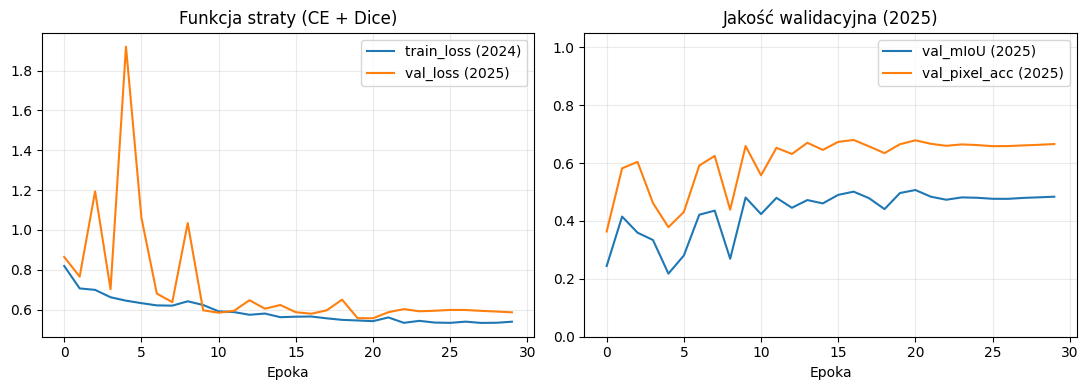

In [76]:
history, best_ckpt_path = train_unet(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    channel_mean=channel_mean,
    channel_std=channel_std,
    model_dir=MODEL_DIR,
    epochs=EPOCHS,
    lr=LR,
    weight_decay=WEIGHT_DECAY,
)
print(f"Zapisano najlepszy model -> {best_ckpt_path} (best val mIoU={max(history['val_miou']):.4f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["train_loss"], label=f"train_loss ({TRAIN_YEAR})")
axes[0].plot(history["val_loss"], label=f"val_loss ({EVAL_YEAR})")
axes[0].set_title("Funkcja straty (CE + Dice)")
axes[0].set_xlabel("Epoka")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(history["val_miou"], label=f"val_mIoU ({EVAL_YEAR})")
axes[1].plot(history["val_acc"], label=f"val_pixel_acc ({EVAL_YEAR})")
axes[1].set_title(f"Jakość walidacyjna ({EVAL_YEAR})")
axes[1].set_xlabel("Epoka")
axes[1].set_ylim(0.0, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

=== Walidacja (2025) (176,860 px) | Accuracy=0.6785 | Cohen's kappa=0.4836 ===
              klasa  support_px  precision  recall      f1     iou
0          0 (inne)       48584     0.8277  0.8503  0.8389  0.7224
1          1 (pole)       91991     0.7439  0.6930  0.7176  0.5595
2  2 (granica_pola)       36285     0.3622  0.4117  0.3854  0.2387
                        Pred: 0 (inne)  Pred: 1 (pole)  Pred: 2 (granica_pola)
True: 0 (inne)                   41312            4677                    2595
True: 1 (pole)                    4523           63753                   23715
True: 2 (granica_pola)            4077           17269                   14939
=== Test niezależny (2025) (177,045 px) | Accuracy=0.6664 | Cohen's kappa=0.4688 ===
              klasa  support_px  precision  recall      f1     iou
0          0 (inne)       48426     0.7931  0.8316  0.8119  0.6833
1          1 (pole)       92300     0.7516  0.6714  0.7092  0.5494
2  2 (granica_pola)       36319     0.3593  0.4335 

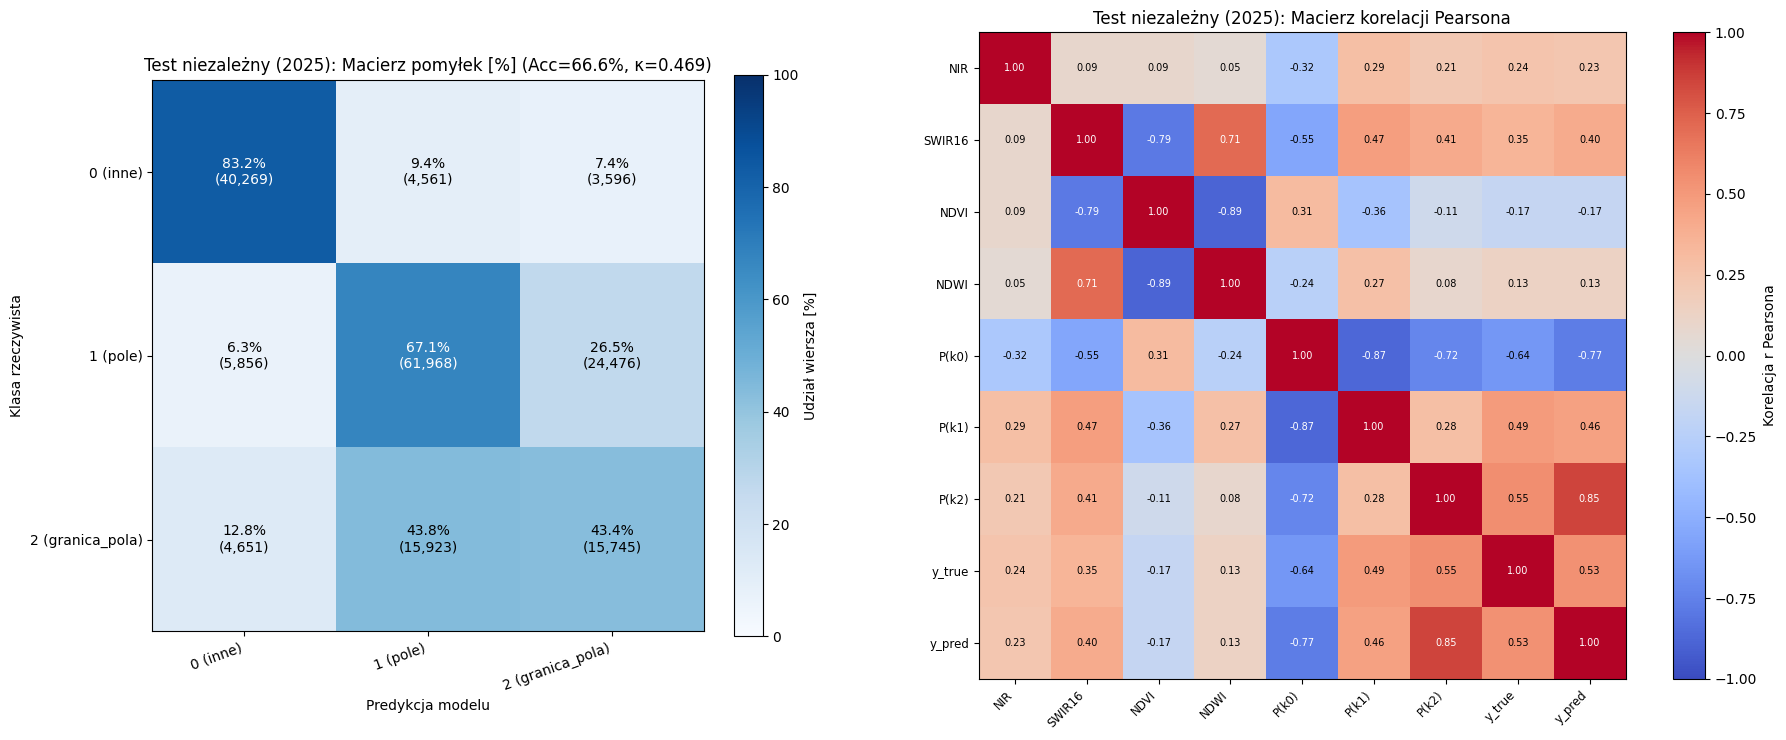

In [77]:
# Ocena na zbiorze walidacyjnym (2025 Val) i niezależnym testowym (2025 Test): macierz pomyłek + macierz korelacji Pearsona
if "best_ckpt_path" in globals() and Path(best_ckpt_path).exists():
    _eval_ckpt = torch.load(best_ckpt_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(_eval_ckpt["model_state_dict"])

band_labels = list(SELECTED_BAND_NAMES)


def evaluate_loader_matrices(model: nn.Module, loader: DataLoader, band_labels: list[str], split_name: str, show_plots: bool = False):
    x_parts, prob_parts, yt_parts, yp_parts = [], [], [], []
    model.eval()
    with torch.no_grad():
        for x_b, y_b in loader:
            x_dev = x_b.to(DEVICE, non_blocking=USE_AMP)
            with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                probs_b = torch.softmax(model(x_dev), dim=1).cpu()
            preds_b = probs_b.argmax(dim=1)
            valid_b = (y_b != IGNORE_INDEX) & (y_b >= 0) & (y_b < NUM_CLASSES)
            if not torch.any(valid_b):
                continue
            x_parts.append(x_b.permute(0, 2, 3, 1)[valid_b].numpy())
            prob_parts.append(probs_b.permute(0, 2, 3, 1)[valid_b].numpy())
            yt_parts.append(y_b[valid_b].numpy())
            yp_parts.append(preds_b[valid_b].numpy())

    X_all = np.concatenate(x_parts, axis=0)
    P_all = np.concatenate(prob_parts, axis=0)
    y_true = np.concatenate(yt_parts, axis=0).astype(np.int64)
    y_pred = np.concatenate(yp_parts, axis=0).astype(np.int64)

    cm = np.bincount(y_true * NUM_CLASSES + y_pred, minlength=NUM_CLASSES * NUM_CLASSES).reshape(NUM_CLASSES, NUM_CLASSES)
    cm_pct = 100.0 * cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    cls_labels = [f"{c} ({CLASS_NAMES.get(c, f'klasa_{c}')})" for c in range(NUM_CLASSES)]
    cm_df = pd.DataFrame(cm, index=[f"True: {l}" for l in cls_labels], columns=[f"Pred: {l}" for l in cls_labels])

    metric_rows = []
    for c in range(NUM_CLASSES):
        tp = int(cm[c, c])
        fp = int(cm[:, c].sum() - tp)
        fn = int(cm[c, :].sum() - tp)
        metric_rows.append({
            "klasa": cls_labels[c], "support_px": int(cm[c, :].sum()),
            "precision": round(tp / (tp + fp), 4) if (tp + fp) > 0 else np.nan,
            "recall": round(tp / (tp + fn), 4) if (tp + fn) > 0 else np.nan,
            "f1": round(2 * tp / (2 * tp + fp + fn), 4) if (2 * tp + fp + fn) > 0 else np.nan,
            "iou": round(tp / (tp + fp + fn), 4) if (tp + fp + fn) > 0 else np.nan,
        })
    metrics_df = pd.DataFrame(metric_rows)

    total_px = max(1, int(cm.sum()))
    p0 = float(np.trace(cm)) / total_px
    pe = float(np.dot(cm.sum(axis=1), cm.sum(axis=0))) / (total_px * total_px)
    kappa = (p0 - pe) / (1.0 - pe) if abs(1.0 - pe) > 1e-12 else 0.0
    print(f"=== {split_name} ({len(y_true):,} px) | Accuracy={p0:.4f} | Cohen's kappa={kappa:.4f} ===")
    _show = globals().get("display", print)
    _show(metrics_df)
    _show(cm_df)

    max_corr_px = 100_000
    idx_sub = np.random.default_rng(SEED).choice(len(y_true), size=max_corr_px, replace=False) if len(y_true) > max_corr_px else slice(None)
    corr_cols = [*band_labels, *(f"P(k{c})" for c in range(NUM_CLASSES)), "y_true", "y_pred"]
    corr_df = pd.DataFrame(np.column_stack([X_all[idx_sub], P_all[idx_sub], y_true[idx_sub], y_pred[idx_sub]]), columns=corr_cols).corr(method="pearson")

    if show_plots:
        fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={"width_ratios": [1.0, 1.55]})
        im_cm = axes[0].imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
        axes[0].set_xticks(range(NUM_CLASSES)); axes[0].set_yticks(range(NUM_CLASSES))
        axes[0].set_xticklabels(cls_labels, rotation=20, ha="right"); axes[0].set_yticklabels(cls_labels)
        axes[0].set_xlabel("Predykcja modelu"); axes[0].set_ylabel("Klasa rzeczywista")
        axes[0].set_title(f"{split_name}: Macierz pomyłek [%] (Acc={100.0 * p0:.1f}%, κ={kappa:.3f})")
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                axes[0].text(j, i, f"{cm_pct[i, j]:.1f}%\n({cm[i, j]:,})", ha="center", va="center", color="white" if cm_pct[i, j] > 55 else "black", fontsize=10)
        plt.colorbar(im_cm, ax=axes[0], fraction=0.046, label="Udział wiersza [%]")

        corr_arr = corr_df.to_numpy(dtype=np.float64)
        cmap_corr = plt.get_cmap("coolwarm").copy()
        cmap_corr.set_bad("#eeeeee")
        im_corr = axes[1].imshow(corr_arr, cmap=cmap_corr, vmin=-1.0, vmax=1.0)
        axes[1].set_xticks(range(len(corr_cols))); axes[1].set_yticks(range(len(corr_cols)))
        axes[1].set_xticklabels(corr_cols, rotation=45, ha="right", fontsize=8.5)
        axes[1].set_yticklabels(corr_cols, fontsize=8.5)
        axes[1].set_title(f"{split_name}: Macierz korelacji Pearsona")
        for i in range(len(corr_cols)):
            for j in range(len(corr_cols)):
                val = corr_arr[i, j]
                axes[1].text(j, i, f"{val:.2f}" if np.isfinite(val) else "—", ha="center", va="center", color="white" if (np.isfinite(val) and abs(val) > 0.65) else "black", fontsize=7)
        plt.colorbar(im_corr, ax=axes[1], fraction=0.038, label="Korelacja r Pearsona")
        plt.tight_layout()
        plt.show()

    return metrics_df, cm, cm_df, corr_df, {"y_true": y_true, "y_pred": y_pred, "acc": p0, "kappa": kappa}


val_metrics_df, val_cm, val_cm_df, val_corr_df, val_summary = evaluate_loader_matrices(
    model, val_loader, band_labels, f"Walidacja ({EVAL_YEAR})", show_plots=False
)
test_metrics_df, test_cm, test_cm_df, test_corr_df, test_summary = evaluate_loader_matrices(
    model, test_loader, band_labels, f"Test niezależny ({EVAL_YEAR})", show_plots=True
)

[aoi_1] Wektoryzacja (4 scen z 2025) -> 20 rozdzielonych pól (133.90 ha)


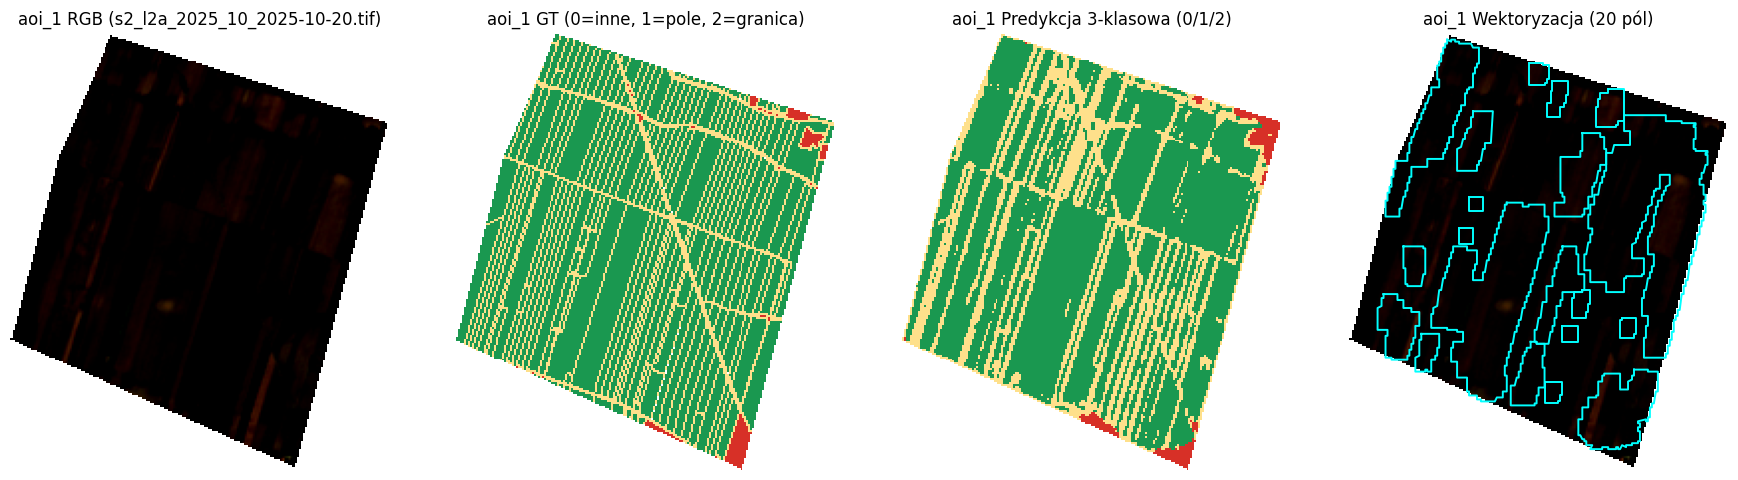

[aoi_3] Wektoryzacja (4 scen z 2025) -> 11 rozdzielonych pól (36.17 ha)


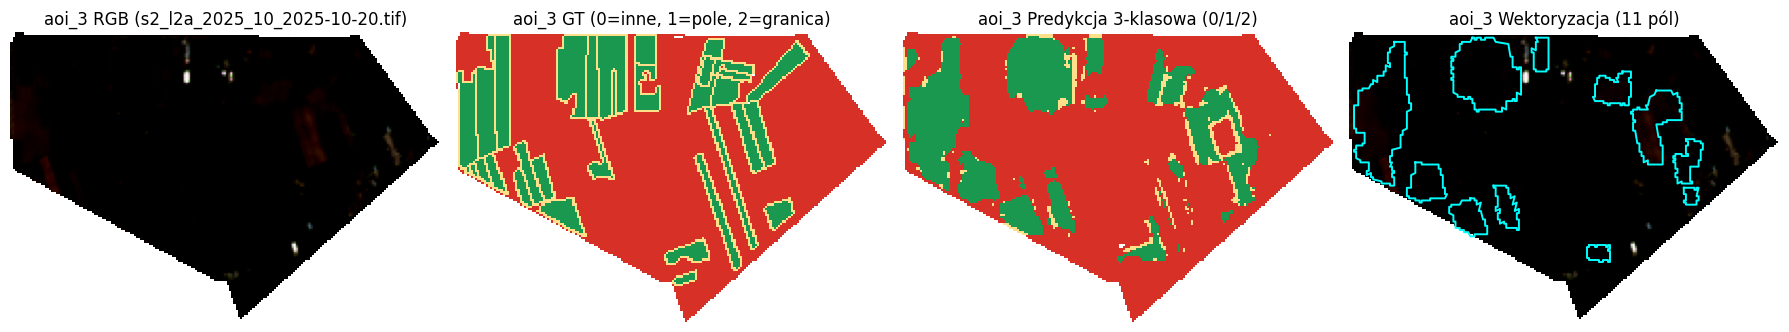

In [126]:
# Wektoryzacja rozdzielonych pól (wykorzystanie klasy granica_pola -> GeoPackage + GeoJSON)
def predict_aoi_field_probabilities(
    model: nn.Module,
    raster_paths: list[Path],
    channel_mean: np.ndarray,
    channel_std: np.ndarray,
    band_indices: list[int] = SELECTED_BAND_INDICES,
    tile_size: int = TILE_SIZE,
    stride: int = STRIDE,
    num_classes: int = NUM_CLASSES,
    ignore_index: int = IGNORE_INDEX,
    device: torch.device = DEVICE,
) -> tuple[np.ndarray, np.ndarray, dict]:
    """Uśrednij 3-klasowe prawdopodobieństwa P(inne, pole, granica_pola) ze scen danego AOI."""
    prob_sum = None
    prob_cnt = None
    ref_profile = None

    model.eval()
    for rpath in raster_paths:
        with rasterio.open(rpath) as src:
            raw = src.read(band_indices).astype(np.float32)
            profile = src.profile.copy()

        _, h, w = raw.shape
        raw_valid = np.all(np.isfinite(raw), axis=0)
        if not np.any(raw_valid):
            continue

        raw_pad, _ = pad_to_grid(raw, np.zeros((h, w), dtype=np.uint8), tile_size=tile_size, ignore_index=ignore_index)
        _, h_pad, w_pad = raw_pad.shape
        norm_pad = np.nan_to_num((raw_pad - channel_mean[:, None, None]) / channel_std[:, None, None], nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

        scene_prob_acc = np.zeros((num_classes, h_pad, w_pad), dtype=np.float32)
        scene_w_acc = np.zeros((h_pad, w_pad), dtype=np.float32)

        with torch.no_grad():
            for y0 in _sliding_starts(h_pad, tile_size, stride):
                for x0 in _sliding_starts(w_pad, tile_size, stride):
                    patch = torch.from_numpy(norm_pad[:, y0 : y0 + tile_size, x0 : x0 + tile_size]).unsqueeze(0).to(device)
                    with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                        probs = torch.softmax(model(patch), dim=1).squeeze(0).cpu().numpy()
                    scene_prob_acc[:, y0 : y0 + tile_size, x0 : x0 + tile_size] += probs
                    scene_w_acc[y0 : y0 + tile_size, x0 : x0 + tile_size] += 1.0

        scene_probs = (scene_prob_acc / np.maximum(scene_w_acc[None, :, :], 1e-6))[:, :h, :w]
        if prob_sum is None:
            prob_sum = np.zeros((num_classes, h, w), dtype=np.float32)
            prob_cnt = np.zeros((h, w), dtype=np.int32)
            ref_profile = profile

        prob_sum[:, raw_valid] += scene_probs[:, raw_valid]
        prob_cnt[raw_valid] += 1

    if prob_sum is None:
        raise ValueError("Brak poprawnych pikseli do predykcji AOI.")

    any_valid = prob_cnt > 0
    mean_probs = np.where(any_valid[None, :, :], prob_sum / np.maximum(prob_cnt[None, :, :], 1), np.nan).astype(np.float32)
    return mean_probs, any_valid, ref_profile


def remove_small_objects(mask, min_size=20):
    labeled, num_features = label(mask)
    if num_features == 0:
        return mask
    sizes = np.bincount(labeled.ravel())
    keep = sizes >= min_size
    keep[0] = False  
    return keep[labeled]

def remove_small_holes(mask, area_threshold=15):
    return ~remove_small_objects(~mask, min_size=area_threshold)

def postprocess_and_vectorize_fields(
    mean_probs: np.ndarray,
    valid_mask: np.ndarray,
    profile: dict,
    out_prefix: Path,
    aoi_name: str,
    prob_threshold: float = PROB_THRESHOLD,
    boundary_threshold: float = BOUNDARY_THRESHOLD,
    min_field_area_ha: float = MIN_FIELD_AREA_HA,
    simplify_tol_m: float = SIMPLIFY_TOL_M,
    morph_kernel_size: int = 5,
    ignore_index: int = IGNORE_INDEX,
) -> tuple[np.ndarray, gpd.GeoDataFrame]:
    """Rozdziel stykające się pola przez klasę granica_pola i zwektoryzuj osobne działki."""
    pred_cls = mean_probs.argmax(axis=0).astype(np.uint8)
    pred_mask = np.where(valid_mask, pred_cls, ignore_index).astype(np.uint8)
    mask_tif_path = out_prefix.parent / f"pred_mask_{aoi_name}.tif"
    mask_tif_path.parent.mkdir(parents=True, exist_ok=True)
    with rasterio.open(mask_tif_path, "w", **{**profile, "count": 1, "dtype": "uint8", "nodata": ignore_index, "compress": "deflate"}) as dst:
        dst.write(pred_mask, 1)
        dst.set_band_description(1, "UNET_PRED_3CLS")

    prob_pole, prob_bnd = mean_probs[1], mean_probs[2]
    interior = valid_mask & np.isfinite(prob_pole) & (prob_pole >= prob_threshold) & (prob_bnd < boundary_threshold)
    if morph_kernel_size and morph_kernel_size > 1:
        morph_struct = np.ones((morph_kernel_size, morph_kernel_size), dtype=bool)
        morph_cross = np.array([[0, 1, 0],
                            [1, 1, 1],
                            [0, 1, 0]], dtype=bool)
        interior = binary_closing(interior, structure=morph_struct)
        interior = binary_opening(interior, structure=morph_struct)
    interior = binary_fill_holes(interior)
    inst_grid, n_inst = nd_label(interior)
    if n_inst > 0 and getattr(profile["crs"], "is_projected", True):
        px_ha = abs(float(profile["transform"].a) * float(profile["transform"].e)) / 10_000.0
        min_px = max(1, int(np.floor(0.5 * min_field_area_ha / px_ha))) if px_ha > 0 else 1
        sizes = np.bincount(inst_grid.ravel())
        keep = sizes >= min_px
        keep[0] = False
        inst_grid = np.where(keep[inst_grid], inst_grid, 0).astype(np.int32)

    if np.any(inst_grid > 0):
        dists, nearest_idx = distance_transform_edt(inst_grid == 0, return_indices=True)
        grow = (inst_grid == 0) & valid_mask & (dists <= 1.5) & ((prob_bnd >= boundary_threshold) | (prob_pole >= prob_threshold))
        inst_expanded = inst_grid.copy()
        inst_expanded[grow] = inst_grid[nearest_idx[0][grow], nearest_idx[1][grow]]
    else:
        inst_expanded = inst_grid

    raw_recs = []
    for geom_dict, val in shapes(inst_expanded, mask=inst_expanded > 0, transform=profile["transform"]):
        pid = int(val)
        if pid <= 0:
            continue
        geom = shape(geom_dict)
        if not geom.is_valid:
            geom = geom.buffer(0)
        if geom.is_empty:
            continue
        m_prob = float(np.nanmean(prob_pole[inst_expanded == pid]))
        raw_recs.append({"aoi": aoi_name, "mean_prob": round(m_prob, 4), "geometry": geom})

    if raw_recs:
        gdf_2180 = gpd.GeoDataFrame(raw_recs, crs=profile["crs"]).to_crs("EPSG:2180")
        gdf_2180["geometry"] = gdf_2180.geometry.apply(lambda g: g if g.is_valid else g.buffer(0))
        gdf_2180["area_ha"] = gdf_2180.geometry.area / 10_000.0
        gdf_2180 = gdf_2180[gdf_2180["area_ha"] >= min_field_area_ha].copy()
        if not gdf_2180.empty and simplify_tol_m > 0:
            gdf_2180["geometry"] = gdf_2180.geometry.simplify(simplify_tol_m, preserve_topology=True).apply(lambda g: g if g.is_valid else g.buffer(0))
            gdf_2180["area_ha"] = (gdf_2180.geometry.area / 10_000.0).round(4)
            gdf_2180 = gdf_2180[gdf_2180["area_ha"] >= min_field_area_ha].copy()
        gdf_2180 = gdf_2180.sort_values("area_ha", ascending=False).reset_index(drop=True)
        gdf_2180.insert(0, "field_id", np.arange(1, len(gdf_2180) + 1, dtype=int))
    else:
        gdf_2180 = gpd.GeoDataFrame(columns=["field_id", "aoi", "mean_prob", "area_ha", "geometry"], geometry="geometry", crs="EPSG:2180")

    gdf_2180.to_file(out_prefix.parent / f"pred_fields_{aoi_name}.gpkg", driver="GPKG")
    gdf_2180.to_crs("EPSG:4326").to_file(out_prefix.parent / f"pred_fields_{aoi_name}.geojson", driver="GeoJSON")
    return pred_mask, gdf_2180


vectorized_by_aoi = {}
for aoi in AOI_DATASETS:
    eval_list = aoi["test_rasters"] or aoi["eval_rasters"]
    mean_probs, valid_m, prof = predict_aoi_field_probabilities(
        model, eval_list, channel_mean, channel_std, band_indices=SELECTED_BAND_INDICES
    )
    pred_m, fields_gdf = postprocess_and_vectorize_fields(mean_probs, valid_m, prof, MODEL_DIR / aoi["name"], aoi["name"])
    vectorized_by_aoi[aoi["name"]] = fields_gdf

    total_ha = float(fields_gdf["area_ha"].sum()) if not fields_gdf.empty else 0.0
    print(f"[{aoi['name']}] Wektoryzacja ({len(eval_list)} scen z {EVAL_YEAR}) -> {len(fields_gdf)} rozdzielonych pól ({total_ha:.2f} ha)")

    with rasterio.open(eval_list[-1]) as s_rgb, rasterio.open(aoi["label_path"]) as s_gt:
        rgb = np.clip(np.moveaxis(s_rgb.read([1, 2, 3]), 0, -1) / 0.30, 0.0, 1.0)
        gt = s_gt.read(1)

    cmap_3 = ListedColormap(["#d73027", "#1a9850", "#fee08b"])
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
    axes[0].imshow(rgb); axes[0].set_title(f"{aoi['name']} RGB ({eval_list[-1].name})")
    axes[1].imshow(np.where(gt == IGNORE_INDEX, np.nan, gt.astype(float)), cmap=cmap_3, vmin=0, vmax=2, interpolation="nearest")
    axes[1].set_title(f"{aoi['name']} GT (0=inne, 1=pole, 2=granica)")
    axes[2].imshow(np.where(pred_m == IGNORE_INDEX, np.nan, pred_m.astype(float)), cmap=cmap_3, vmin=0, vmax=2, interpolation="nearest")
    axes[2].set_title(f"{aoi['name']} Predykcja 3-klasowa (0/1/2)")

    axes[3].imshow(rgb)
    if not fields_gdf.empty:
        inv_tf = ~prof["transform"]
        for geom in fields_gdf.to_crs(prof["crs"]).geometry:
            for p in (list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]):
                xs, ys = p.exterior.xy
                px_x, px_y = zip(*(inv_tf * (xv, yv) for xv, yv in zip(xs, ys)))
                axes[3].plot(px_x, px_y, color="#00ffff", linewidth=1.4)
    axes[3].set_title(f"{aoi['name']} Wektoryzacja ({len(fields_gdf)} pól)")
    for ax in axes:
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()